# Laboratorium 2 — Sieci rekurencyjne: budowa i uczenie
Sprawozdanie: wpływ liczby jednostek ukrytych (`hidden`), długości okna (`OKNO`) i typu komórki (RNN/LSTM/GRU)
na prognozę kolejnej próbki szeregu czasowego.

Warunki wspólne: epoki=20, lr=1e-2, batch=64, 3 ziarna (0, 1, 2), wynik = `np.mean(hist[-5:])`, zmieniany jest tylko jeden czynnik naraz.

In [1]:
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0); np.random.seed(0)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Urządzenie:', DEVICE)

Urządzenie: cpu


## 1. Dane i okna (jak w notatniku wyjściowym)

In [2]:
def generuj_szereg(n=2000):
    t = np.linspace(0, 100, n)
    y = np.sin(t) + 0.1*np.sin(3*t) + 0.05*np.random.randn(n)
    return y.astype(np.float32)

seria = generuj_szereg()

def zrob_okna(seria, okno=30):
    X, Y = [], []
    for i in range(len(seria)-okno):
        X.append(seria[i:i+okno]); Y.append(seria[i+okno])
    X = np.array(X, dtype=np.float32)[..., None]  # [N, okno, 1]
    Y = np.array(Y, dtype=np.float32)[:, None]     # [N, 1]
    return X, Y

def przygotuj(okno):
    # tworzenie okien + podział chronologiczny 80/20 (wywoływane od nowa dla każdego OKNO)
    X, Y = zrob_okna(seria, okno)
    n_tr = int(0.8*len(X))
    return (torch.tensor(X[:n_tr]).to(DEVICE), torch.tensor(Y[:n_tr]).to(DEVICE),
            torch.tensor(X[n_tr:]).to(DEVICE), torch.tensor(Y[n_tr:]).to(DEVICE))

DANE = {o: przygotuj(o) for o in [10, 30, 60, 120]}
for o, (a, b, c, d) in DANE.items():
    print(f'OKNO={o:3d}  Xtr={tuple(a.shape)}  Xte={tuple(c.shape)}')

OKNO= 10  Xtr=(1592, 10, 1)  Xte=(398, 10, 1)
OKNO= 30  Xtr=(1576, 30, 1)  Xte=(394, 30, 1)
OKNO= 60  Xtr=(1552, 60, 1)  Xte=(388, 60, 1)
OKNO=120  Xtr=(1504, 120, 1)  Xte=(376, 120, 1)


## 2. Model i pętla uczenia (z dodaną stratą treningową)

In [3]:
class ModelRNN(nn.Module):
    def __init__(self, hidden=32, typ='RNN'):
        super().__init__()
        rnn = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[typ]
        self.rnn = rnn(input_size=1, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

def trenuj(model, Xtr, Ytr, Xte, Yte, epoki=30, lr=1e-2, batch=64):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    strata = nn.MSELoss()
    hist, hist_tr = [], []
    n = len(Xtr)
    for ep in range(epoki):
        model.train(); perm = torch.randperm(n)
        for i in range(0, n, batch):
            idx = perm[i:i+batch]
            opt.zero_grad()
            loss = strata(model(Xtr[idx]), Ytr[idx])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
        model.eval()
        with torch.no_grad():
            hist.append(strata(model(Xte), Yte).item())
            hist_tr.append(strata(model(Xtr), Ytr).item())   # strata treningowa
    return hist, hist_tr

def liczba_param(model):
    return sum(p.numel() for p in model.parameters())

## 3. Punkt odniesienia (pkt 1)

In [4]:
Xtr, Ytr, Xte, Yte = DANE[30]
heur = {o: ((d[3] - d[2][:, -1])**2).mean().item() for o, d in DANE.items()}
print('Heurystyka „ostatnia próbka” (test MSE) wg okna:')
for o, v in heur.items(): print(f'  OKNO={o:3d}: {v:.5f}')

torch.manual_seed(0)
m0 = ModelRNN(hidden=32, typ='RNN')
h0, h0_tr = trenuj(m0, Xtr, Ytr, Xte, Yte, epoki=30)     # model bazowy, jak w notatniku (30 epok)
print(f'\nModel bazowy RNN, hidden=32, OKNO=30, 30 epok:  test MSE: pierwsza epoka {h0[0]:.4f}, ostatnia {h0[-1]:.4f}, '
      f'średnia z ostatnich 5 = {np.mean(h0[-5:]):.5f}')

Heurystyka „ostatnia próbka” (test MSE) wg okna:
  OKNO= 10: 0.00628
  OKNO= 30: 0.00631
  OKNO= 60: 0.00633
  OKNO=120: 0.00631

Model bazowy RNN, hidden=32, OKNO=30, 30 epok:  test MSE: pierwsza epoka 0.0078, ostatnia 0.0038, średnia z ostatnich 5 = 0.00386


## 4. Funkcje pomocnicze eksperymentów

In [5]:
EPOKI, LR, BATCH, SEEDS = 20, 1e-2, 64, (0, 1, 2)
WYNIKI = {}

def uruchom(typ, hidden, okno):
    Xtr, Ytr, Xte, Yte = DANE[okno]
    r = dict(typ=typ, hidden=hidden, okno=okno, mse=[], czas=[], H=[], HTR=[])
    for seed in SEEDS:
        torch.manual_seed(seed); np.random.seed(seed)
        model = ModelRNN(hidden=hidden, typ=typ)
        t0 = time.perf_counter()
        h, h_tr = trenuj(model, Xtr, Ytr, Xte, Yte, epoki=EPOKI, lr=LR, batch=BATCH)
        r['czas'].append(time.perf_counter() - t0)
        r['mse'].append(float(np.mean(h[-5:])))
        r['H'].append(h); r['HTR'].append(h_tr)
        if seed == 0:
            model.eval()
            with torch.no_grad():
                r['pred200'] = model(Xte[:200]).cpu().numpy().ravel().tolist()
            r['true200'] = Yte[:200].cpu().numpy().ravel().tolist()
    r['params'] = liczba_param(model)
    r['mean'] = float(np.mean(r['mse'])); r['std'] = float(np.std(r['mse']))
    r['t'] = float(np.mean(r['czas']))
    WYNIKI[(typ, hidden, okno)] = r
    return r

def tabela(nazwa, konfiguracje, heur_okna):
    print(f'=== {nazwa} ===')
    print(f'{"konfiguracja":<28}{"parametry":>10}{"test MSE (śr ± odch.)":>26}{"czas [s]":>10}')
    for o in heur_okna:
        print(f'{"heurystyka (ostatnia próbka), OKNO="+str(o):<28}{"-":>10}{heur[o]:>26.5f}{"-":>10}')
    for k in konfiguracje:
        r = WYNIKI[k]
        nm = f'{r["typ"]}, hidden={r["hidden"]}, OKNO={r["okno"]}'
        print(f'{nm:<28}{r["params"]:>10}{r["mean"]:>17.5f} ± {r["std"]:.5f}{r["t"]:>10.1f}')

def wykres(konfiguracje, tytul, plik):
    plt.figure(figsize=(9, 4))
    for k in konfiguracje:
        r = WYNIKI[k]
        plt.plot(np.mean(r['H'], axis=0), label=f'{r["typ"]} h={r["hidden"]} okno={r["okno"]}')
    plt.yscale('log'); plt.xlabel('epoka'); plt.ylabel('test MSE (średnia z 3 ziaren)')
    plt.title(tytul); plt.legend(fontsize=8); plt.grid(alpha=.3); plt.tight_layout()
    plt.savefig(plik, dpi=130); plt.show()

## 5. Eksperyment A — liczba jednostek (GRU, OKNO=30)
**Hipoteza (sformułowana przed uruchomieniem):** zwiększanie `hidden` z 8 do 64 obniży MSE, ale z wyraźnie malejącym zyskiem;
różnice powyżej 16–32 jednostek będą rzędu rozrzutu między ziarnami, bo szum (σ² ≈ 0,0025) wyznacza dolną granicę błędu.

=== Eksperyment A (GRU, OKNO=30) ===
konfiguracja                 parametry     test MSE (śr ± odch.)  czas [s]
heurystyka (ostatnia próbka), OKNO=30         -                   0.00631         -
GRU, hidden=8, OKNO=30             273          0.00380 ± 0.00004       1.1
GRU, hidden=16, OKNO=30            929          0.00374 ± 0.00002       1.3
GRU, hidden=32, OKNO=30           3393          0.00376 ± 0.00001       1.6
GRU, hidden=64, OKNO=30          12929          0.00375 ± 0.00008       2.4


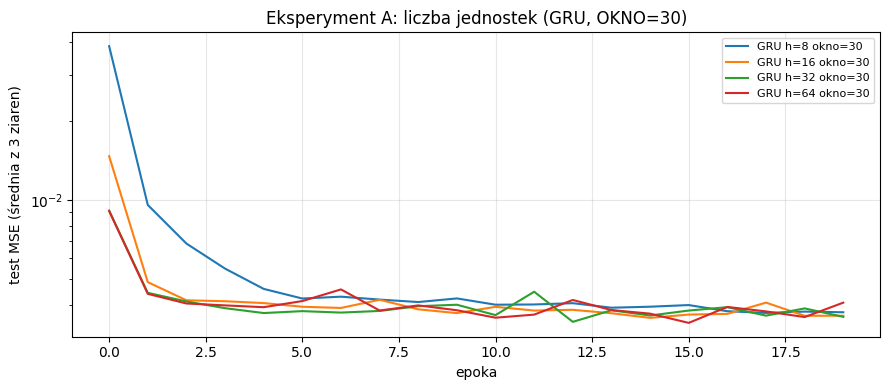

In [6]:
KA = [('GRU', h, 30) for h in (8, 16, 32, 64)]
for k in KA: uruchom(*k)
tabela('Eksperyment A (GRU, OKNO=30)', KA, [30])
wykres(KA, 'Eksperyment A: liczba jednostek (GRU, OKNO=30)', 'wykres_A.png')

## 6. Eksperyment B — długość okna (GRU, hidden=32)
**Hipoteza (sformułowana przed uruchomieniem):** okno 10 będzie wyraźnie gorsze (za mało kontekstu, by rozpoznać fazę i kierunek sygnału),
poprawa wypłaszczy się przy oknach 30–60, a okno 120 nie da dalszej poprawy lub lekko pogorszy wynik (dłuższy łańcuch BPTT, mniej okien).

=== Eksperyment B (GRU, hidden=32) ===
konfiguracja                 parametry     test MSE (śr ± odch.)  czas [s]
heurystyka (ostatnia próbka), OKNO=10         -                   0.00628         -
heurystyka (ostatnia próbka), OKNO=30         -                   0.00631         -
heurystyka (ostatnia próbka), OKNO=60         -                   0.00633         -
heurystyka (ostatnia próbka), OKNO=120         -                   0.00631         -
GRU, hidden=32, OKNO=10           3393          0.00414 ± 0.00019       0.6
GRU, hidden=32, OKNO=30           3393          0.00376 ± 0.00001       1.6
GRU, hidden=32, OKNO=60           3393          0.00343 ± 0.00021       3.0
GRU, hidden=32, OKNO=120          3393          0.00344 ± 0.00019       6.3


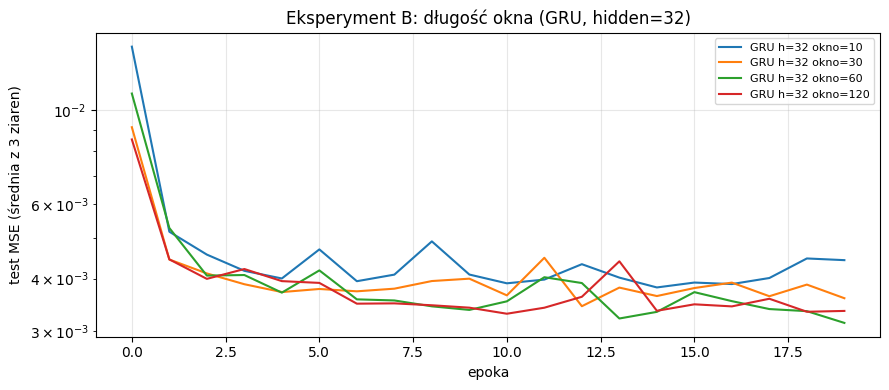

In [7]:
KB = [('GRU', 32, o) for o in (10, 30, 60, 120)]
for k in KB: uruchom(*k)
tabela('Eksperyment B (GRU, hidden=32)', KB, [10, 30, 60, 120])
wykres(KB, 'Eksperyment B: długość okna (GRU, hidden=32)', 'wykres_B.png')

## 7. Eksperyment C — typ komórki (hidden=32, OKNO=10 i 120)

=== Eksperyment C (hidden=32) ===
konfiguracja                 parametry     test MSE (śr ± odch.)  czas [s]
heurystyka (ostatnia próbka), OKNO=10         -                   0.00628         -
heurystyka (ostatnia próbka), OKNO=120         -                   0.00631         -
RNN, hidden=32, OKNO=10           1153          0.00417 ± 0.00025       0.3
LSTM, hidden=32, OKNO=10          4513          0.00415 ± 0.00011       0.7
GRU, hidden=32, OKNO=10           3393          0.00414 ± 0.00019       0.6
RNN, hidden=32, OKNO=120          1153          0.00400 ± 0.00001       2.1
LSTM, hidden=32, OKNO=120         4513          0.00375 ± 0.00013       6.2
GRU, hidden=32, OKNO=120          3393          0.00344 ± 0.00019       6.3


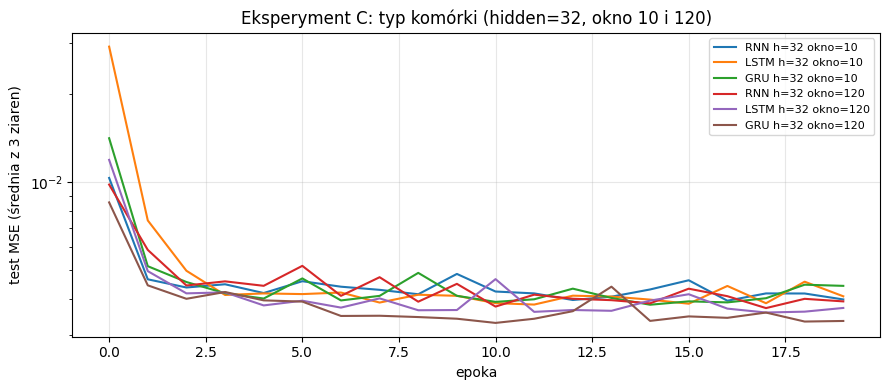

In [8]:
KC = [(t, 32, o) for o in (10, 120) for t in ('RNN', 'LSTM', 'GRU')]
for k in KC:
    if k not in WYNIKI: uruchom(*k)
tabela('Eksperyment C (hidden=32)', KC, [10, 120])
wykres(KC, 'Eksperyment C: typ komórki (hidden=32, okno 10 i 120)', 'wykres_C.png')

## 8. Najlepsza konfiguracja: krzywe train/test oraz predykcja

Najlepsza konfiguracja (wg średniego test MSE): ('GRU', 32, 60) MSE = 0.00343 ± 0.00021


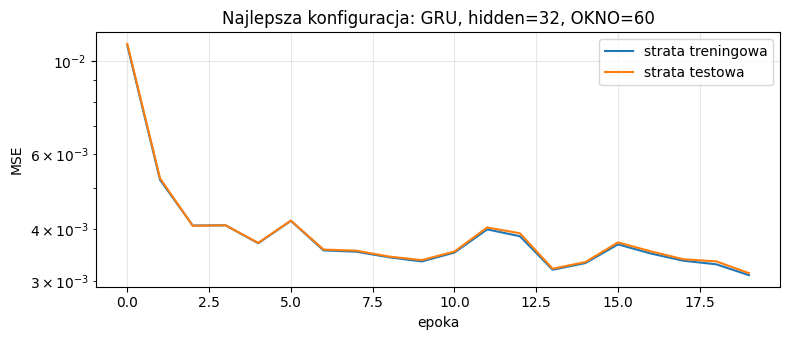

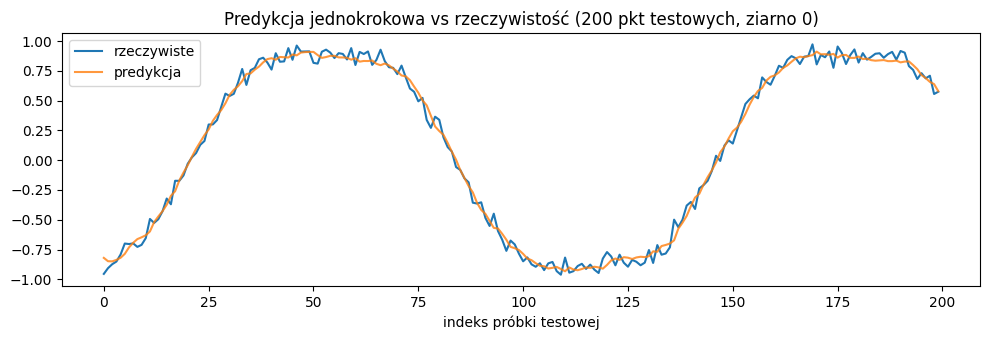

In [9]:
najl = min(WYNIKI, key=lambda k: WYNIKI[k]['mean'])
r = WYNIKI[najl]
print('Najlepsza konfiguracja (wg średniego test MSE):', najl, f'MSE = {r["mean"]:.5f} ± {r["std"]:.5f}')

plt.figure(figsize=(8, 3.5))
plt.plot(np.mean(r['HTR'], axis=0), label='strata treningowa')
plt.plot(np.mean(r['H'], axis=0), label='strata testowa')
plt.yscale('log'); plt.xlabel('epoka'); plt.ylabel('MSE'); plt.legend(); plt.grid(alpha=.3)
plt.title(f'Najlepsza konfiguracja: {najl[0]}, hidden={najl[1]}, OKNO={najl[2]}')
plt.tight_layout(); plt.savefig('wykres_najlepszy_krzywe.png', dpi=130); plt.show()

plt.figure(figsize=(10, 3.5))
plt.plot(r['true200'], label='rzeczywiste')
plt.plot(r['pred200'], label='predykcja', alpha=.8)
plt.legend(); plt.xlabel('indeks próbki testowej'); plt.title('Predykcja jednokrokowa vs rzeczywistość (200 pkt testowych, ziarno 0)')
plt.tight_layout(); plt.savefig('wykres_najlepszy_predykcja.png', dpi=130); plt.show()